In [51]:
# Project Name: Titanic Survival
# DataSet Link: https://www.kaggle.com/datasets/ashishkumarjayswal/titanic-datasets

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (12, 8)
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [53]:
df = pd.read_csv('titanic.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    object 
 4   Sex          418 non-null    object 
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    object 
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     object 
 11  Embarked     418 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 39.3+ KB


In [55]:
# droping Cabin
df.drop(columns=['Cabin', 'PassengerId', 'Name', 'Ticket'], inplace=True)

In [56]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,34.5,0,0,7.8292,Q
1,1,3,female,47.0,1,0,7.0000,S
2,0,2,male,62.0,0,0,9.6875,Q
3,0,3,male,27.0,0,0,8.6625,S
4,1,3,female,22.0,1,1,12.2875,S


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  418 non-null    int64  
 1   Pclass    418 non-null    int64  
 2   Sex       418 non-null    object 
 3   Age       332 non-null    float64
 4   SibSp     418 non-null    int64  
 5   Parch     418 non-null    int64  
 6   Fare      417 non-null    float64
 7   Embarked  418 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 26.2+ KB


In [58]:
df['Age'].isnull().sum()

86

In [59]:
# filling na with random Age within mean - std(), mean + std()
Random_Age = np.random.randint(df['Age'].mean() - df['Age'].std(), df['Age'].mean() + df['Age'].std(), size=df['Age'].isnull().sum())

# fill na value with random age
df['Age'][np.isnan(df['Age'])] = Random_Age

<ipython-input-59-e6e567111dfd>:5: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df['Age'][np.isnan(df['Age'])] = Random_Age
<ipython-input-59-e6e567111dfd>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a 

In [60]:
df['Fare'].fillna(df['Fare'].mean(), inplace=True)

<ipython-input-60-76719988b203>:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Fare'].fillna(df['Fare'].mean(), inplace=True)


In [61]:
df.isnull().sum()

,0
Survived,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Embarked,0


In [62]:
# making family size column
df['Family_Size'] = df['SibSp'] + df['Parch'] + 1

In [63]:
# drop columns - SibSp, Parch
df.drop(columns=['SibSp', 'Parch'], inplace=True)

In [64]:
# EDA - Exploratory Data Analysis

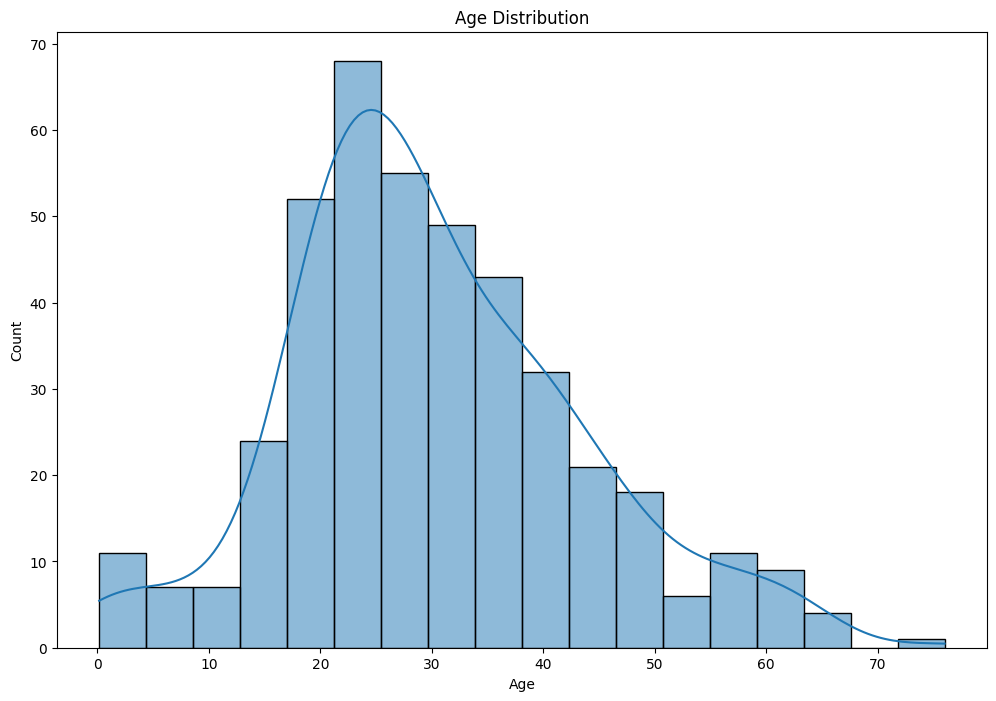

In [65]:
# Age Distribution
sns.histplot(df['Age'], kde=True)
plt.title("Age Distribution")
plt.show()

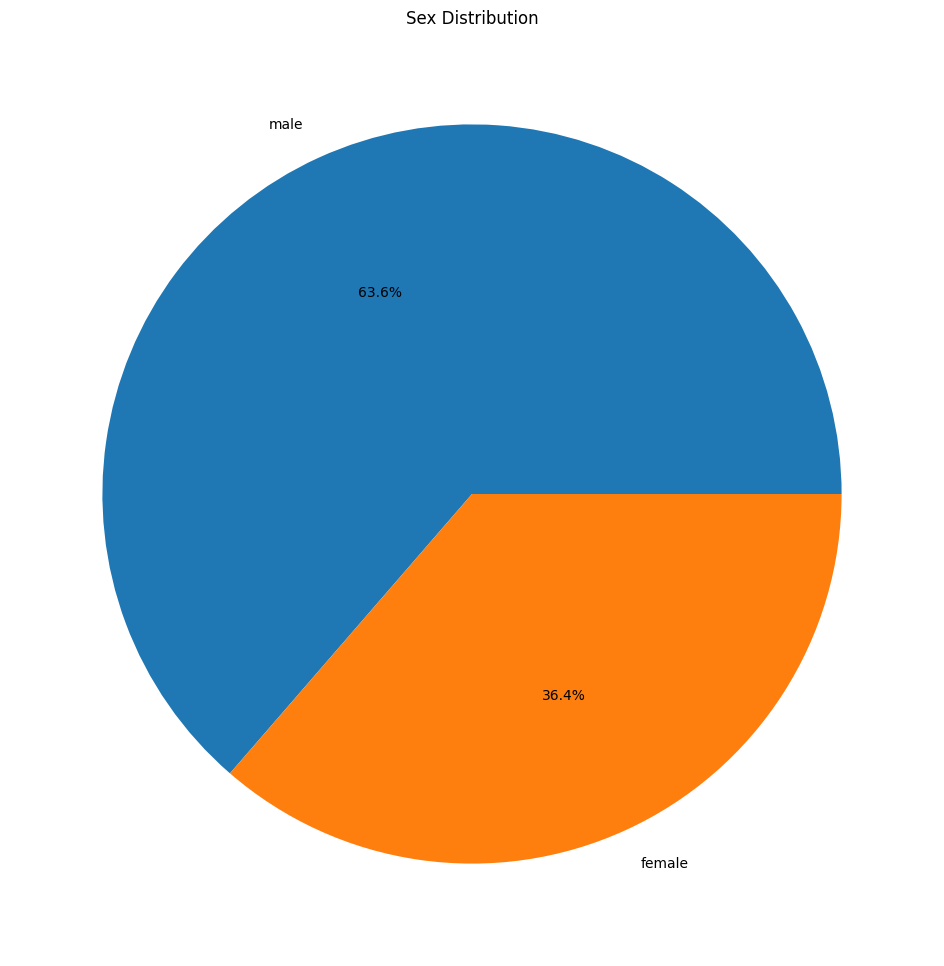

In [66]:
# Sex distribution pie chart
plt.figure(figsize=(16, 12))
plt.pie(df['Sex'].value_counts(), labels=df['Sex'].value_counts().index, autopct='%1.1f%%')
plt.title("Sex Distribution")
plt.show()

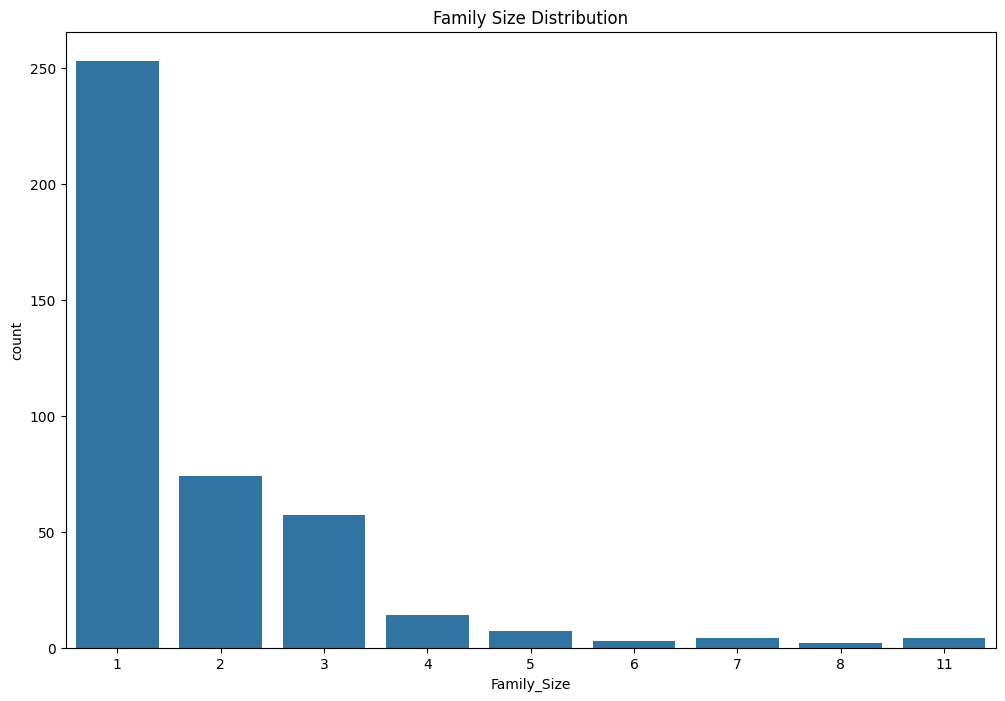

In [67]:
# family size distribution
sns.barplot(x=df['Family_Size'].value_counts().index, y=df['Family_Size'].value_counts())
plt.title("Family Size Distribution")
plt.show()

In [68]:
# machine learning part

In [69]:
# replace Family_Size numerical to categorical
def FamilyGroup(Number):
  if Number == 1:
    return 'Single'
  elif Number > 1 and Number < 5:
    return 'Medium'
  else:
    return 'Large'

df['Family_Size'] = df['Family_Size'].apply(FamilyGroup)

In [70]:
df

,Survived,Pclass,Sex,Age,Fare,Embarked,Family_Size
0,0,3,male,34.5,7.8292,Q,Single
1,1,3,female,47.0,7.0000,S,Medium
2,0,2,male,62.0,9.6875,Q,Single
3,0,3,male,27.0,8.6625,S,Single
4,1,3,female,22.0,12.2875,S,Medium
...,...,...,...,...,...,...,...
413,0,3,male,32.0,8.0500,S,Single
414,1,1,female,39.0,108.9000,C,Single
415,0,3,male,38.5,7.2500,S,Single
416,0,3,male,19.0,8.0500,S,Single


In [79]:
df

,Survived,Pclass,Sex,Age,Fare,Embarked,Family_Size
0,0,3,male,34.5,7.8292,Q,Single
1,1,3,female,47.0,7.0000,S,Medium
2,0,2,male,62.0,9.6875,Q,Single
3,0,3,male,27.0,8.6625,S,Single
4,1,3,female,22.0,12.2875,S,Medium
...,...,...,...,...,...,...,...
413,0,3,male,32.0,8.0500,S,Single
414,1,1,female,39.0,108.9000,C,Single
415,0,3,male,38.5,7.2500,S,Single
416,0,3,male,19.0,8.0500,S,Single


In [80]:
# encoding categorical data
df = pd.get_dummies(df, columns=['Sex', 'Embarked', 'Family_Size', 'Pclass'], drop_first=True)

In [81]:
df

,Survived,Age,Fare,Sex_male,Embarked_Q,Embarked_S,Family_Size_Medium,Family_Size_Single,Pclass_2,Pclass_3
0,0,34.5,7.8292,True,True,False,False,True,False,True
1,1,47.0,7.0000,False,False,True,True,False,False,True
2,0,62.0,9.6875,True,True,False,False,True,True,False
3,0,27.0,8.6625,True,False,True,False,True,False,True
4,1,22.0,12.2875,False,False,True,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...
413,0,32.0,8.0500,True,False,True,False,True,False,True
414,1,39.0,108.9000,False,False,False,False,True,False,False
415,0,38.5,7.2500,True,False,True,False,True,False,True
416,0,19.0,8.0500,True,False,True,False,True,False,True


In [82]:
# extract independent and dependet variable
X = df.drop(columns=['Survived'])
y = df['Survived']

In [90]:
# train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=41)

In [101]:
# training model
model = LogisticRegression(max_iter=500, C=0.01)
model.fit(X_train, y_train)

LogisticRegression(C=0.01, max_iter=500)

In [102]:
# predicting
y_pred = model.predict(X_test)

In [103]:
# checking accuracy_score
print("Accuracy Score: ",accuracy_score(y_test, y_pred))

Accuracy Score:  0.7023809523809523
